In [104]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## Class labels
- -1 = noise
- 1 = ceiling shot
- 2 = power shot
- 3 = waving dash
- 5 = air dribble
- 6 = front flick
- 7 = musty flick

In [105]:
label_name_map = {
    -1: "noise",
    1: "ceiling shot",
    2: "power shot",
    3: "waving dash",
    5: "air dribble",
    6: "front flick",
    7: "musty flick",
}
valid_labels = set(label_name_map.keys())

## Load + Parse Raw Dataset

Dataset parsing logic:
- First line = 18 feature names
- Single int lines in {-1, 1, 2, 3, 5, 6, 7} are class labels
- All following 18-value rows belong to that sample until the next label

In [106]:

"""
    Parse the .data file into variable sequences.

    Returns:
        feature_names: list[str]
        X_sequences: list[pd.DataFrame] (one per sample)
        y_labels: list[int]
"""
def parse_skillshots_data(file_path: Path):
    
    lines = [ln.strip() for ln in file_path.read_text(encoding="utf-8", errors="replace").splitlines() if ln.strip()]
    if not lines:
        raise ValueError("Input file is empty.")

    feature_names = lines[0].split()
    if len(feature_names) != 18:
        raise ValueError(f"Expected 18 feature names in header.")

    X_sequences = []
    y_labels = []

    current_label = None
    current_rows = []


    def flush_current_sample():
        if current_label is None:
            return
        if len(current_rows) == 0:
            return
        else:
            seq_df = pd.DataFrame(current_rows, columns=feature_names)
        X_sequences.append(seq_df)
        y_labels.append(current_label)
    

    for line_num, line in enumerate(lines[1:], start=2):
        tokens = line.split()

        #Detect label only lines
        if len(tokens) == 1:
            try:
                maybe_label = int(tokens[0])
            except ValueError:
                maybe_label = None

            if maybe_label in valid_labels:
                flush_current_sample()
                current_label = maybe_label
                current_rows = []
                continue

            raise ValueError(
                f"Line {line_num}: single-token line '{tokens[0]}' is not a valid label."
            )

        #Otherwise this should be a numeric row with 18 values
        if len(tokens) != 18:
            raise ValueError(
                f"Line {line_num}: expected 18 numeric values or a single label. Got {len(tokens)} token(s)."
            )

        try:
            row_values = [float(tok) for tok in tokens]
        except ValueError as exc:
            raise ValueError(f"Line {line_num}: non-numeric value found in feature row.") from exc

        current_rows.append(row_values)

    #Flush final sample
    flush_current_sample()

    return feature_names, X_sequences, y_labels




"""
    Convert one sample into one fixed length feature row.
        - For each of 18 columns: mean, std, min, max
        - For binary columns: sum
        - duration = max(Time)
"""
def engineer_sample_features(seq_df: pd.DataFrame, feature_names: list[str]):
    
    row = {}

    #Determine binary columns 
    expected_binary_cols = ["up", "accelerate", "slow", "goal", "left", "boost", "camera", "down", "right", "slide", "jump"]
    binary_cols = [c for c in expected_binary_cols if c in feature_names]

    for col in feature_names:
    
        series = seq_df[col]
        row[f"{col}_mean"] = float(series.mean())
        row[f"{col}_std"] = float(series.std(ddof=0))
        row[f"{col}_min"] = float(series.min())
        row[f"{col}_max"] = float(series.max())

    #Sum only for binary columns
    for col in binary_cols:
        row[f"{col}_sum"] = float(seq_df[col].sum())

    #Duration feature from Time
    if "Time" in seq_df.columns and len(seq_df):
        row["duration"] = float(seq_df["Time"].max())

    return row

### Read in Data

In [107]:
data_path = Path("data/rocket_league_skillshots.data")

feature_names, X_sequences, y_labels = parse_skillshots_data(data_path)

engineered_rows = []
for seq_df, label in zip(X_sequences, y_labels):
    feat_row = engineer_sample_features(seq_df, feature_names)
    feat_row["label"] = label
    feat_row["class_name"] = label_name_map[label]
    engineered_rows.append(feat_row)

#Turn list into a dataframe
df = pd.DataFrame(engineered_rows).fillna(0)

sorted_labels = sorted(valid_labels)
label_to_index = {lab: idx for idx, lab in enumerate(sorted_labels)}
index_to_label = {idx: lab for lab, idx in label_to_index.items()}
index_to_name = {idx: label_name_map[lab] for idx, lab in index_to_label.items()}
df["target"] = df["label"].map(label_to_index)

print("Parsing + feature engineering complete.")
print("Number of samples:", len(df))
print("Number of columns:", df.shape[1])
display(df.head())

Parsing + feature engineering complete.
Number of samples: 298
Number of columns: 87


,BallAcceleration_mean,BallAcceleration_std,BallAcceleration_min,BallAcceleration_max,Time_mean,Time_std,Time_min,Time_max,DistanceWall_mean,DistanceWall_std,...,boost_sum,camera_sum,down_sum,right_sum,slide_sum,jump_sum,duration,label,class_name,target
0,-3853.867885,35118.068950,-195896.923082,33405.144871,2.326591,1.464055,0.0,5.070104,3770.785313,172.166242,...,7.0,2.0,0.0,26.0,7.0,9.0,5.070104,6,front flick,5
1,-848.813985,24746.867916,-57692.175539,127059.240710,3.261104,2.439726,0.0,8.161284,1698.631795,1389.537152,...,8.0,4.0,0.0,39.0,18.0,10.0,8.161284,-1,noise,0
2,-1264.766385,27831.333948,-89020.813365,124246.293754,3.453076,2.821939,0.0,8.130110,1796.122941,1496.993284,...,10.0,3.0,0.0,34.0,4.0,7.0,8.130110,-1,noise,0
3,-2133.341430,9238.505488,-39930.029136,8232.787624,1.612082,0.898798,0.0,3.610510,1072.541739,950.041522,...,7.0,3.0,0.0,23.0,8.0,11.0,3.610510,-1,noise,0
4,-7148.505767,30389.928898,-141736.497607,5120.925237,1.311509,1.027101,0.0,3.681763,3800.485000,121.139418,...,8.0,3.0,0.0,16.0,7.0,5.0,3.681763,-1,noise,0


In [108]:
df.isnull().sum()

BallAcceleration_mean    0
BallAcceleration_std     0
BallAcceleration_min     0
BallAcceleration_max     0
Time_mean                0
                        ..
jump_sum                 0
duration                 0
label                    0
class_name               0
target                   0
Length: 87, dtype: int64

### Label Column Map:
    -1 - noise
    1 - ceiling shot
    2 - power shot
    3 - wave dash
    5 - air dribble
    6 - front flick
    7 - musty flick

### Target Column Map:
    0 - noise
    1 - ceiling shot
    2 - power shot
    3 - wave dash
    4 - air dribble
    5 - front flick
    6 - musty flick

Target is used to train model

## Data Analysis

### Count Plot

DataFrame shape: (298, 87)

Class counts:
label
-1    43
 1    30
 2    60
 3    38
 5    45
 6    46
 7    36
Name: count, dtype: int64


C:\Users\Ethan Bennett\AppData\Local\Temp\ipykernel_11884\1033916705.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


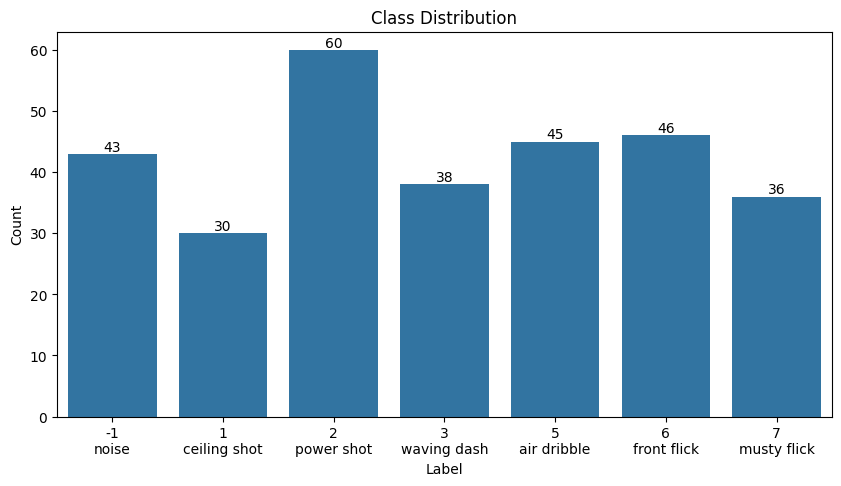

In [109]:
print("DataFrame shape:", df.shape)
print("\nClass counts:")
print(df["label"].value_counts().sort_index())

plt.figure(figsize=(10, 5))
order = sorted(df["label"].unique())
ax = sns.countplot(data=df, x="label", order=order)
ax.set_xticklabels(
    [f"{label}\n{label_name_map.get(label, 'unknown')}" for label in order]
)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{int(height)}",
        (p.get_x() + p.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=10
    )
plt.title("Class Distribution")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

### Feature Correlation & Heatmap

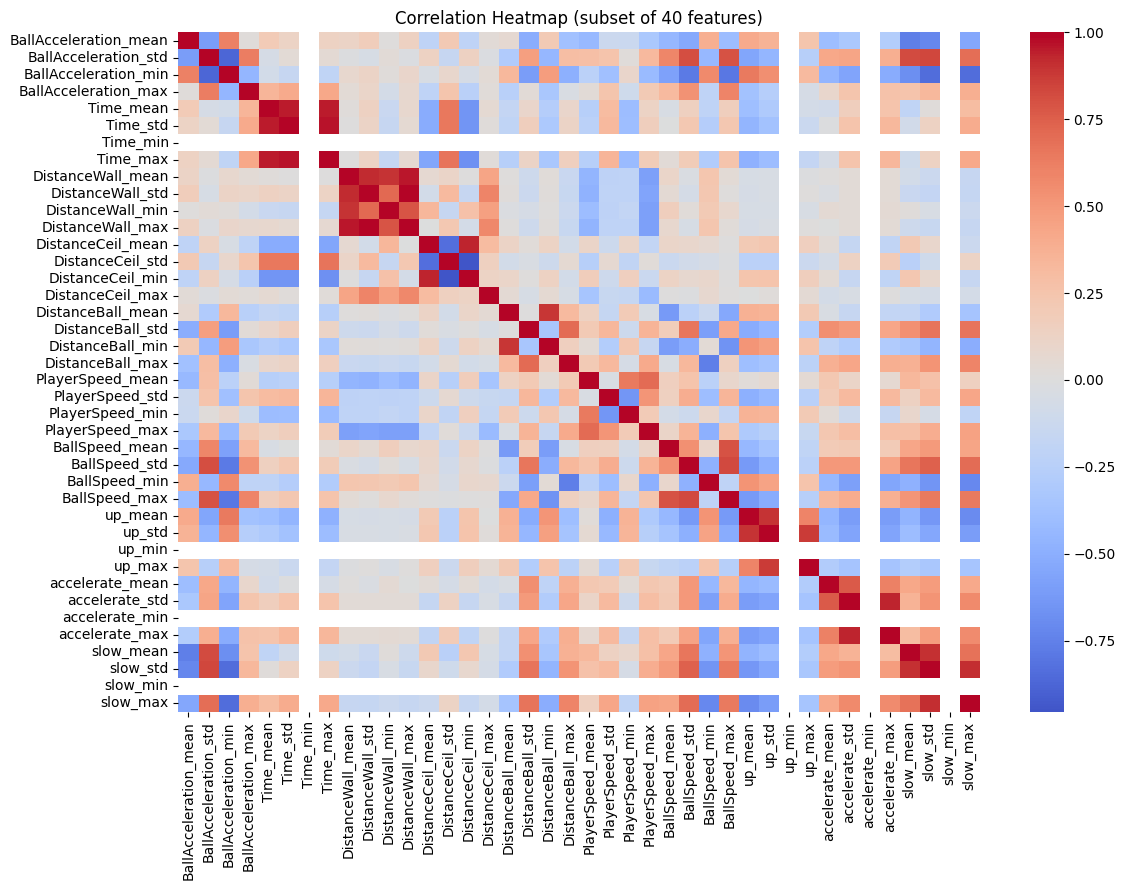

In [110]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_cols = ["label", "target"]
numeric_feature_cols = [c for c in numeric_cols if c not in exclude_cols]
heatmap_cols = numeric_feature_cols[:40]

corr = df[heatmap_cols].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (subset of 40 features)")
plt.tight_layout()
plt.show()

In [111]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_cols = ["label", "target"]
numeric_feature_cols = [c for c in numeric_cols if c not in exclude_cols]
heatmap_cols = numeric_feature_cols[:]

corr = df[heatmap_cols].corr()

pairs = []

for col1 in corr.columns:
    for col2 in corr.columns:
        if col1 >= col2:
            continue

        #Base name before final underscore
        base1 = "_".join(col1.split("_")[:-1])
        base2 = "_".join(col2.split("_")[:-1])

        #Skip same keyword groups
        if base1 == base2:
            continue

        value = corr.loc[col1, col2]

        pairs.append((col1, col2, value))

corr_df = pd.DataFrame(pairs, columns=["Feature 1", "Feature 2", "Correlation"])

#Sort by strongest correlation
corr_df["Abs Corr"] = corr_df["Correlation"].abs()

print("From All Features:")
corr_df.sort_values("Abs Corr", ascending=False).drop(columns="Abs Corr").head(20)


From All Features:


,Feature 1,Feature 2,Correlation
543,Time_max,duration,1.000000
431,Time_std,duration,0.964274
375,Time_mean,duration,0.948813
3297,jump_sum,right_sum,0.850622
193,BallAcceleration_min,slow_std,-0.844808
195,BallAcceleration_min,slow_max,-0.840444
230,BallAcceleration_min,slow_sum,-0.840444
113,BallAcceleration_std,slow_std,0.833935
112,BallAcceleration_std,slow_mean,0.823145
101,BallAcceleration_std,BallSpeed_std,0.810513


## Preprocessing

In [145]:
X = df[numeric_feature_cols].values
y = df["target"].values

#Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)

#Scale data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


#Convert to tensors
X_train = torch.tensor(X_train_scaled)
X_test = torch.tensor(X_test_scaled)
y_train = torch.tensor(y_train)
y_test = torch.tensor(y_test)

print("Train X shape:", X_train.shape)
print("Test X shape:", X_test.shape)


Train X shape: torch.Size([223, 84])
Train y shape: torch.Size([223])
Test X shape: torch.Size([75, 84])
Test y shape: torch.Size([75])


In [193]:
from torch.utils.data import TensorDataset, DataLoader

batch_size = 16

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [166]:
import torch.nn as nn

class LinearClassificationModel(nn.Module):

    def __init__(self, input_features, output_classes, sigma=0.01):

        super(LinearClassificationModel, self).__init__()

        self.net = nn.Sequential(                           
            nn.Linear(input_features, output_classes)   
        )

        nn.init.normal_(self.net[0].weight, mean=0, std=sigma)
        nn.init.zeros_(self.net[0].bias)

    def forward(self, X):
        return self.net(X)

In [168]:
class CrossEntropyLossWrapper:

    def __init__(self):

        self.criterion = nn.CrossEntropyLoss()
    
    def __call__(self, predictions, targets):
        
        return self.criterion(predictions, targets)

In [207]:
class SGDOptimizer:

    def __init__(self, model_params, lr=0.01):

        self.optimizer = torch.optim.SGD(model_params, lr=lr)
    
    def zero_grad(self):

        self.optimizer.zero_grad()
    
    def step(self):
        
        self.optimizer.step()




class AdamOptimizer:

    def __init__(self, model_params, lr=0.01):

        self.optimizer = torch.optim.Adam(model_params, lr=lr)
    
    def zero_grad(self):

        self.optimizer.zero_grad()
    
    def step(self):
        
        self.optimizer.step()

In [217]:

input_size = 84
num_classes = 7

lr = 0.01

model = LinearClassificationModel(input_size, num_classes)
lossfn = CrossEntropyLossWrapper()
optimizer = AdamOptimizer(model.parameters(), lr=lr)

epochs = 10
total_epoch_loss = []
final_accuracy   = []

model.train()

for epoch in range(epochs):

    total_loss = 0.0
    correct    = 0
    total      = 0

    for idx, (batchX, batchy) in enumerate(train_loader):
        
        optimizer.zero_grad()
        y_hat = model(batchX)            
        loss = lossfn(y_hat, batchy) 
        loss.backward()                    
        optimizer.step() 

        predicted = torch.argmax(y_hat, dim=1)
        correct += (predicted == batchy).sum().item()
        total += batchy.size(0)
        total_loss += loss.item()

    epoch_loss = total_loss / len(train_loader)
    epoch_accuracy = 100.0 * correct / total

    total_epoch_loss.append(epoch_loss)
    final_accuracy.append(epoch_accuracy)

    print(f"Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_accuracy:.2f}%")

Epoch [1/10] | Loss: 1.2118 | Accuracy: 60.99%
Epoch [2/10] | Loss: 0.6169 | Accuracy: 80.72%
Epoch [3/10] | Loss: 0.4654 | Accuracy: 87.00%
Epoch [4/10] | Loss: 0.3863 | Accuracy: 86.55%
Epoch [5/10] | Loss: 0.3279 | Accuracy: 89.69%
Epoch [6/10] | Loss: 0.2988 | Accuracy: 90.13%
Epoch [7/10] | Loss: 0.2714 | Accuracy: 91.48%
Epoch [8/10] | Loss: 0.2537 | Accuracy: 92.83%
Epoch [9/10] | Loss: 0.2387 | Accuracy: 93.72%
Epoch [10/10] | Loss: 0.2204 | Accuracy: 94.62%


In [218]:
model.eval()

correct = 0
total   = 0

with torch.no_grad():
    for batchX, batchy in test_loader:

        outputs   = model(batchX)                    
        predicted = torch.argmax(outputs, dim=1)     

        correct += (predicted == batchy).sum().item()
        total   += batchy.size(0)

test_accuracy = 100 * correct / total
print(f"\nTest accuracy: {test_accuracy:.2f}%")


Test accuracy: 80.00%


Accuracy:  0.8
              precision    recall  f1-score   support

       noise      0.667     0.545     0.600        11
ceiling shot      0.667     0.857     0.750         7
  power shot      0.933     0.933     0.933        15
 waving dash      0.909     1.000     0.952        10
 air dribble      1.000     0.909     0.952        11
 front flick      0.833     0.417     0.556        12
 musty flick      0.600     1.000     0.750         9

    accuracy                          0.800        75
   macro avg      0.801     0.809     0.785        75
weighted avg      0.820     0.800     0.790        75



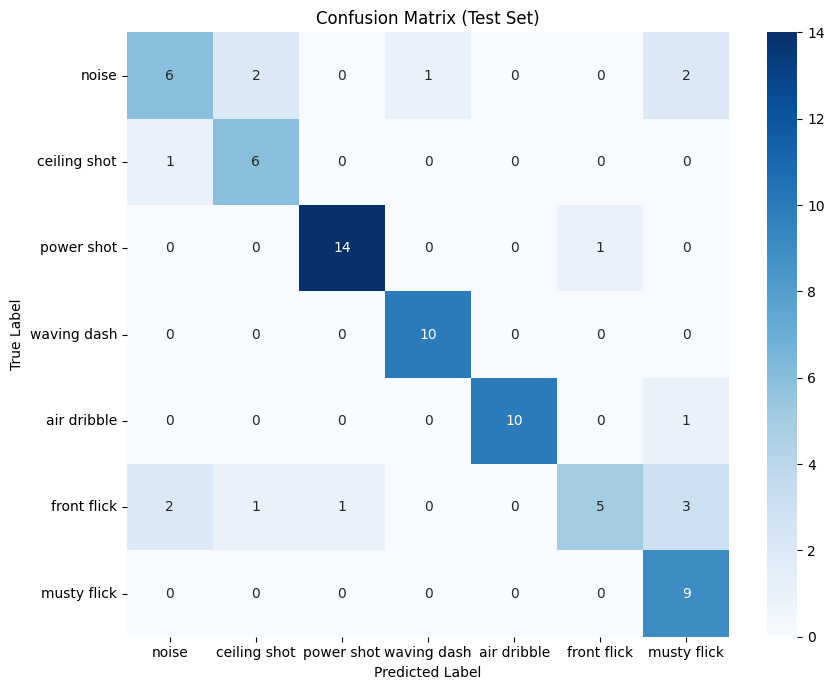

In [239]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

model.eval()
all_true = []
all_pred = []

with torch.no_grad():
    for batchX, batchy in test_loader:
        outputs = model(batchX)
        preds = torch.argmax(outputs, dim=1)
        all_true.extend(batchy.numpy())
        all_pred.extend(preds.numpy())

cm = confusion_matrix(all_true, all_pred)

accuracy = accuracy_score(all_true, all_pred)
print("Accuracy: ", accuracy)
print(classification_report(all_true, all_pred, target_names=class_names, digits=3))

class_names = [index_to_name[i] for i in range(num_classes)]


plt.figure(figsize=(9, 7))
sns.heatmap(
cm,
annot=True,
fmt="d",
cmap="Blues",
xticklabels=class_names,
yticklabels=class_names,
)
plt.title("Confusion Matrix (Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
